![Segmentation de glomérules sur des biopsies rénales](https://raw.githubusercontent.com/yayefatou-lam/segmentation-glomerules/main/assets/banner.png)

**Yaye Fatou Lam** et **Imad Asennane** · Défi IA du Master 2 IOSD (Image, Optimisation et Sciences des Données), Université de Bordeaux · 2026 · *projet en cours*

| $\color{#C2643F}{\mathbf{0{,}883}}$ | $\color{#C2643F}{\mathbf{53}}$ | $\color{#C2643F}{\mathbf{24{,}5\,\text{M}}}$ | $\color{#C2643F}{\mathbf{\approx 12\,\text{min}}}$ |
|:---:|:---:|:---:|:---:|
| Dice sur le test, 8 patchs jamais vus | patchs histologiques annotés, 1024 × 1024 | paramètres (U-Net + ResNet34) | d'entraînement sur un GPU T4 |

> $\color{#55623F}{\bullet}$ **Sommaire**
>
> 1. Le problème
> 2. Démarche et modèles testés
> 3. Configuration
> 4. Les données
> 5. Découpage train / validation / test
> 6. Augmentation des données
> 7. Le modèle
> 8. Entraînement
> 9. Post-traitement
> 10. Évaluation sur le test
> 11. Bilan et suite

## $\color{#C2643F}{\mathbf{01}}$ &nbsp; Le problème

Les **glomérules** sont les petites unités de filtration du rein. Sur une biopsie rénale, le médecin pathologiste les repère et les examine pour diagnostiquer et suivre une maladie rénale chronique. Ce travail est long et en partie subjectif : un outil qui les détecte automatiquement aide au diagnostic.

**La tâche :** pour chaque patch de tissu (image de $1024 \times 1024$ pixels), prédire le masque des glomérules, c'est-à-dire indiquer pour chaque pixel s'il appartient à un glomérule. C'est de la **segmentation d'images**.

**Le score du challenge** est le coefficient de Dice entre le masque prédit $A$ et le masque annoté $B$, calculé à la taille d'origine de l'image :

$$
\text{Dice}(A, B) = \frac{2\,|A \cap B|}{|A| + |B|} .
$$

Il vaut 1 quand les deux masques coïncident et 0 quand ils ne se recouvrent pas du tout.


> $\color{#8A6420}{\bullet}$ **La difficulté**
>
> Peu de données (53 patchs annotés), des colorations différentes d'une lame à l'autre (HE, PAS, PASM…), et des glomérules qui ne couvrent qu'environ 5 % des pixels : un modèle qui prédirait « pas de glomérule » partout aurait raison sur 95 % des pixels, avec un Dice nul.

## $\color{#C2643F}{\mathbf{02}}$ &nbsp; Démarche et modèles testés

Ce notebook présente notre modèle final. Avant d'y arriver, on a fait cinq entraînements préliminaires : le meilleur était un **U-Net dont l'encodeur est un ResNet34 pré-entraîné sur ImageNet**, avec deux pas d'apprentissage et une décroissance en cosinus. On a gardé ce réseau et corrigé ce qui le limitait :

| Limite du modèle précédent | Changement dans ce notebook |
| --- | --- |
| Images réduites de 1024 à 512 : bords des glomérules perdus | entraînement sur des **morceaux de 512 × 512 en pleine résolution**, prédiction sur l'**image entière** |
| 10 mises à jour des poids par époque | **4 morceaux tirés au hasard par image** et par époque, la moitié centrés sur un glomérule |
| Augmentation limitée (miroir, rotations, luminosité) | + **zoom aléatoire** et **variations de coloration** |
| Score mesuré à 512 pendant l'entraînement | Dice de validation mesuré **à la taille d'origine**, comme dans le challenge |

Résultats de nos essais :

| Modèle | Dice validation | Dice test | Retenu |
| --- | ---: | ---: | --- |
| Meilleur des 5 essais préliminaires (images réduites en 512) | 0,883 | 0,867 | non |
| $\color{#C2643F}{\bullet}$ **Modèle de ce notebook** (pleine résolution) | 0,882 | 0,883 | **oui** |
| Même modèle + post-traitement (section 09) | 0,886 |  | non, gain trop faible |
| Moyenne de 3 modèles entraînés avec 3 graines |  |  | non, moins bonne qu'un modèle seul lors de notre essai |

> $\color{#55623F}{\bullet}$ **Méthode**
>
> Le jeu de test n'a servi qu'une seule fois, à la fin : tous les choix (époque, post-traitement, ensemble ou non) ont été faits sur la validation. Les scores varient d'un entraînement à l'autre, car les calculs sur GPU ne sont pas parfaitement reproductibles : lors d'un entraînement précédent, ce même modèle avait obtenu 0,891 en validation et 0,898 sur le test.

## $\color{#C2643F}{\mathbf{03}}$ &nbsp; Configuration

Le notebook est prévu pour Google Colab avec un GPU (Exécution > Modifier le type d'exécution > GPU). Sur GPU, l'entraînement prend une dizaine de minutes ; sur CPU, plusieurs heures.

In [1]:
import random
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Patch
from torch.utils.data import DataLoader, Dataset

In [8]:
# Chemins
DATA_DIR = Path("/content/data/Set02_Glom_train_clean")           # paires <nom>.png / <nom>_mask.tif
DRIVE_ZIP = "/content/drive/MyDrive/defi IA/Project 1/Set02_Glom_train_clean.zip"
SAVE_DIR = Path("outputs")                                         # poids du modèle
ASSETS_DIR = Path("assets")                                        # figures reprises dans le README
SAVE_DIR.mkdir(exist_ok=True)
ASSETS_DIR.mkdir(exist_ok=True)

# Entraînement
CROP = 512              # taille des morceaux d'entraînement, en pixels à pleine résolution
CROPS_PER_IMAGE = 4     # morceaux tirés au hasard dans chaque image, à chaque époque
BATCH_SIZE = 8
EPOCHS = 80
LR_ENCODER = 1e-4       # encodeur pré-entraîné : petits pas, il sait déjà reconnaître des formes
LR_DECODER = 1e-3       # décodeur initialisé au hasard : pas plus grands
SEED = 42

device = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = device == "cuda"      # précision mixte sur GPU : environ 2 fois plus rapide


def set_seed(seed):
    """Fixe toutes les graines aléatoires (Python, NumPy, PyTorch)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


print("device :", device)

device : cuda


In [9]:
# Palette terracotta, utilisée pour toutes les figures
COLORS = {
    "terracotta": "#C2643F",
    "brique": "#9A4A2E",
    "argile": "#E3A587",
    "sable": "#EADBC8",
    "creme": "#FBF6F0",
    "sauge": "#7E8C69",
    "ocre": "#D4A24C",
    "encre": "#3B2F2A",
    "taupe": "#8C7B70",
}
RGB = {name: tuple(int(c[i:i + 2], 16) for i in (1, 3, 5)) for name, c in COLORS.items()}    # pour OpenCV
MASK_CMAP = LinearSegmentedColormap.from_list("masque", ["#FFFFFF", COLORS["terracotta"]])

plt.rcParams.update({
    "figure.facecolor": COLORS["creme"],
    "axes.facecolor": COLORS["creme"],
    "savefig.facecolor": COLORS["creme"],
    "axes.edgecolor": COLORS["taupe"],
    "axes.labelcolor": COLORS["encre"],
    "axes.titlecolor": COLORS["encre"],
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": COLORS["sable"],
    "xtick.color": COLORS["taupe"],
    "ytick.color": COLORS["taupe"],
    "text.color": COLORS["encre"],
    "legend.frameon": False,
    "font.size": 11,
})


def finish(fig, title=None, name=None):
    """Titre de la figure, mise en page, enregistrement éventuel dans assets/, affichage."""
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=14)
    fig.tight_layout()
    if name:
        fig.savefig(ASSETS_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## $\color{#C2643F}{\mathbf{04}}$ &nbsp; Les données

Chaque image `<nom>.png` a son masque `<nom>_mask.tif`, dans lequel 0 correspond au fond et 1, 2, 3… à chaque glomérule. Le jeu de données fourni est volontairement imparfait : certains masques n'ont pas d'image (on les ignore) et quelques images font $1024 \times 1023$ pixels au lieu de $1024 \times 1024$.

Toutes les images sont lues une seule fois et gardées en mémoire, à leur taille d'origine. Elles restent au format BGR, celui d'OpenCV : la conversion en RGB est faite seulement pour l'affichage et à l'entrée du modèle.


> $\color{#8A6420}{\bullet}$ **Données non publiées**
>
> Les patchs ont été fournis dans le cadre du cours et ne sont pas inclus dans ce dépôt. Sur Colab, la cellule suivante les copie depuis Google Drive.

In [11]:
if not DATA_DIR.exists():                  # sur Colab : copie des données depuis Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    !cp "{DRIVE_ZIP}" /content/data.zip
    !unzip -q /content/data.zip -d /content/data

print("dossier de données trouvé :", DATA_DIR.exists())

dossier de données trouvé : True


In [15]:
def read_image(path):
    """Image BGR, uint8, de forme (H, W, 3)."""
    return cv2.imread(str(path))


def read_mask(path):
    """Masque binaire : True sur les pixels de glomérule."""
    return cv2.imread(str(path), cv2.IMREAD_UNCHANGED) > 0


images = sorted((p for p in DATA_DIR.rglob("*.png") if not p.name.startswith("._")), key=lambda p: p.name)
pairs = [(p, p.with_name(f"{p.stem}_mask.tif")) for p in images if p.with_name(f"{p.stem}_mask.tif").exists()]
n_masks = len([p for p in DATA_DIR.rglob("*_mask.tif") if not p.name.startswith("._")])

data = {img_path: (read_image(img_path), read_mask(mask_path)) for img_path, mask_path in pairs}

sizes = {}
for img, mask in data.values():
    sizes[img.shape[:2]] = sizes.get(img.shape[:2], 0) + 1

print(f"{len(images)} images, {n_masks} masques, {len(pairs)} paires ({n_masks - len(pairs)} masques sans image, ignorés)")
print("tailles des images :", sizes)
print(f"part des pixels de glomérule : {np.mean([m.mean() for _, m in data.values()]):.1%}")

53 images, 66 masques, 53 paires (13 masques sans image, ignorés)
tailles des images : {(1024, 1024): 48, (1024, 1023): 5}
part des pixels de glomérule : 5.4%


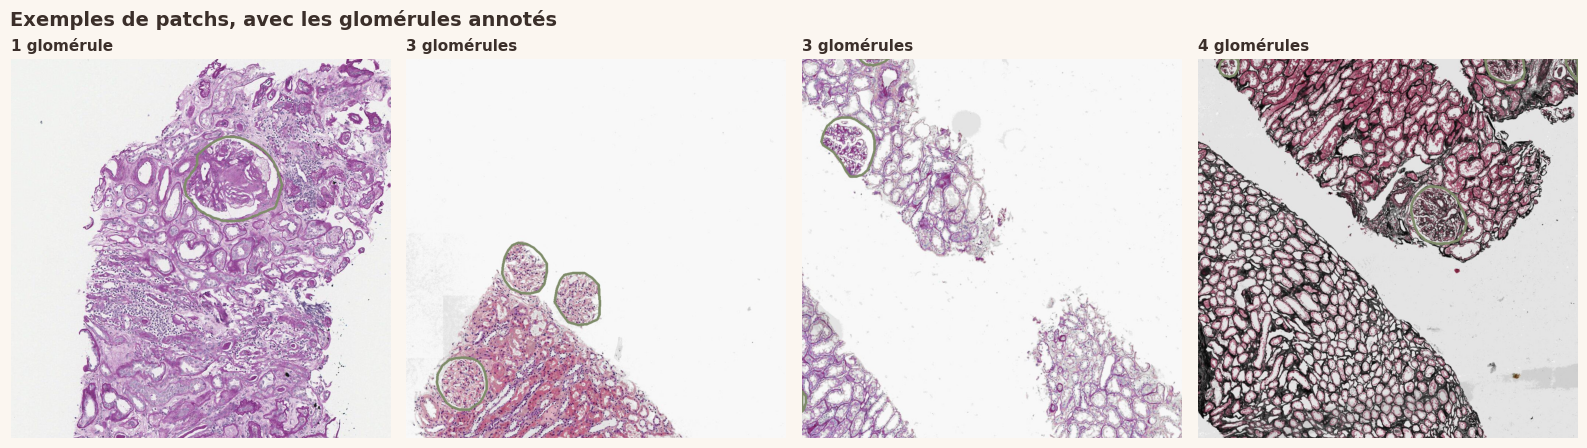

In [16]:
def count_glomeruli(mask):
    """Nombre de glomérules d'un masque binaire : une composante connexe par glomérule."""
    return cv2.connectedComponents(mask.astype(np.uint8))[0] - 1


def draw_contours(img, mask, color, thickness=6):
    """Image RGB avec les contours des glomérules du masque, dans la couleur donnée."""
    view = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(view, contours, -1, color, thickness)
    return view


examples = [pairs[i][0] for i in np.linspace(0, len(pairs) - 1, 4).astype(int)]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, img_path in zip(axes, examples):
    img, mask = data[img_path]
    n = count_glomeruli(mask)
    ax.imshow(draw_contours(img, mask, RGB["sauge"]))
    ax.set_title(f"{n} glomérule{'s' if n > 1 else ''}", fontsize=11)
    ax.axis("off")
finish(fig, "Exemples de patchs, avec les glomérules annotés", name="apercu_donnees")

## $\color{#C2643F}{\mathbf{05}}$ &nbsp; Découpage train / validation / test

On répartit les patchs en 70 % / 15 % / 15 %, lame par lame et avec une graine fixe, pour que chaque ensemble contienne des patchs des deux lames. C'est le même découpage que pour nos essais préliminaires : les patchs de test sont les mêmes, les scores sont donc comparables.

| Ensemble | Rôle |
| --- | --- |
| Train | apprendre les poids du réseau |
| Validation | choisir la meilleure époque et le post-traitement |
| Test | évaluation finale, utilisée une seule fois |

In [17]:
def slide_of(path):
    """Identifiant de la lame d'origine, au début du nom du fichier."""
    return path.name.split("_")[0]


slides = sorted({slide_of(img_path) for img_path, _ in pairs})

random.seed(SEED)
train_pairs, val_pairs, test_pairs = [], [], []
for slide in slides:
    group = [pair for pair in pairs if slide_of(pair[0]) == slide]
    random.shuffle(group)
    n_train, n_val = round(0.70 * len(group)), round(0.15 * len(group))
    train_pairs += group[:n_train]
    val_pairs += group[n_train:n_train + n_val]
    test_pairs += group[n_train + n_val:]
    print(f"lame {slide[:8]} : {len(group)} patchs")

print(f"train : {len(train_pairs)}   validation : {len(val_pairs)}   test : {len(test_pairs)}")

lame 2fda166d : 11 patchs
lame 4389 : 42 patchs
train : 37   validation : 8   test : 8


## $\color{#C2643F}{\mathbf{06}}$ &nbsp; Augmentation des données

Avec seulement 37 patchs d'entraînement, le réseau risque d'apprendre les images par cœur. À chaque fois qu'un patch est utilisé, on en tire donc une version modifiée au hasard :

1. **un morceau d'environ 512 × 512** en pleine résolution, avec un zoom aléatoire (taille multipliée par 0,8 à 1,25, puis ramenée à 512). Une fois sur deux, le morceau est centré sur un glomérule, pour que le modèle en voie assez ;
2. **un miroir et un quart de tour** au hasard, appliqués à l'image et au masque ;
3. **des variations de luminosité, de contraste, de teinte et de saturation** (image seulement), pour imiter les différences de coloration entre lames.

La même transformation géométrique est toujours appliquée à l'image et à son masque. La validation et le test ne sont jamais augmentés.

In [18]:
def random_crop(img, mask, ys, xs):
    """Morceau carré d'environ CROP pixels (zoom aléatoire), centré une fois sur deux sur un pixel de glomérule."""
    h, w = mask.shape
    s = min(int(CROP * random.uniform(0.8, 1.25)), h, w)
    if len(ys) > 0 and random.random() < 0.5:
        k = random.randrange(len(ys))
        cy, cx = ys[k], xs[k]
    else:
        cy, cx = random.randrange(h), random.randrange(w)
    y0 = int(np.clip(cy - s // 2, 0, h - s))
    x0 = int(np.clip(cx - s // 2, 0, w - s))
    img = img[y0:y0 + s, x0:x0 + s]
    mask = mask[y0:y0 + s, x0:x0 + s].astype(np.uint8)
    if s != CROP:
        img = cv2.resize(img, (CROP, CROP), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (CROP, CROP), interpolation=cv2.INTER_NEAREST)
    return img, mask


def flip_and_rotate(img, mask):
    """Miroir (une fois sur deux) et quart de tour aléatoire, identiques pour l'image et le masque."""
    if random.random() < 0.5:
        img, mask = img[:, ::-1], mask[:, ::-1]
    k = random.randint(0, 3)
    return np.ascontiguousarray(np.rot90(img, k)), np.ascontiguousarray(np.rot90(mask, k))


def change_colors(img):
    """Contraste et luminosité aléatoires."""
    contrast, brightness = random.uniform(0.8, 1.2), random.uniform(-20, 20)
    return np.clip(img.astype(np.float32) * contrast + brightness, 0, 255).astype(np.uint8)


def change_stain(img):
    """Teinte et saturation aléatoires, pour imiter une autre coloration."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + random.uniform(-8, 8)) % 180
    hsv[..., 1] = np.clip(hsv[..., 1] * random.uniform(0.8, 1.2), 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)


def augment(img, mask, ys, xs):
    """Version modifiée au hasard d'un patch d'entraînement et de son masque."""
    img, mask = random_crop(img, mask, ys, xs)
    img, mask = flip_and_rotate(img, mask)
    return change_stain(change_colors(img)), mask

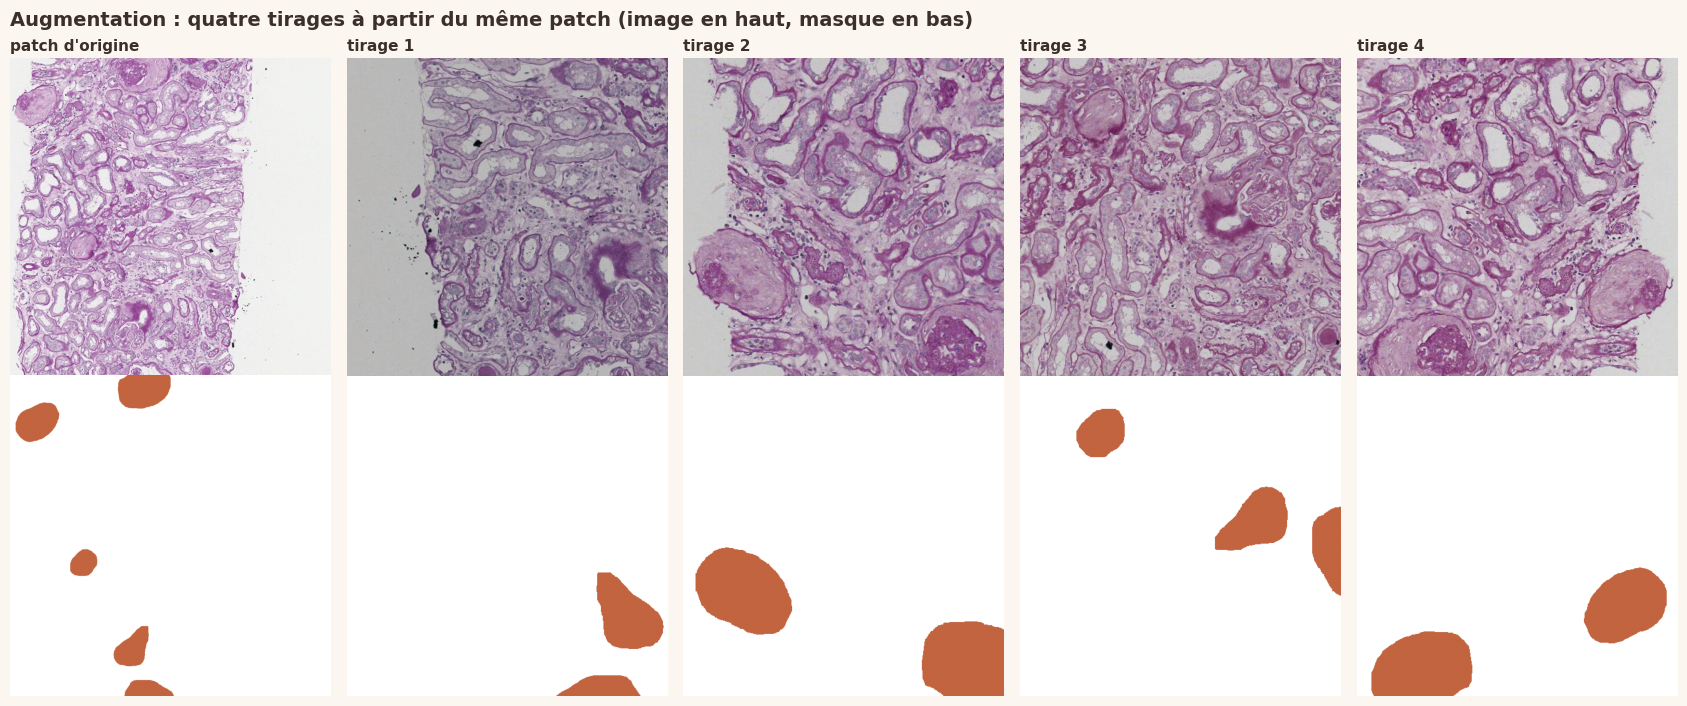

In [19]:
img, mask = data[train_pairs[0][0]]
ys, xs = np.nonzero(mask)

fig, axes = plt.subplots(2, 5, figsize=(17, 7.2))
axes[0, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[1, 0].imshow(mask, cmap=MASK_CMAP)
axes[0, 0].set_title("patch d'origine", fontsize=11)
for j in range(1, 5):
    a_img, a_mask = augment(img, mask, ys, xs)
    axes[0, j].imshow(cv2.cvtColor(a_img, cv2.COLOR_BGR2RGB))
    axes[1, j].imshow(a_mask, cmap=MASK_CMAP, vmin=0, vmax=1)
    axes[0, j].set_title(f"tirage {j}", fontsize=11)
for ax in axes.ravel():
    ax.axis("off")
finish(fig, "Augmentation : quatre tirages à partir du même patch (image en haut, masque en bas)", name="augmentation")

### Des morceaux tirés à la volée

`TrainCrops` fournit `CROPS_PER_IMAGE` morceaux par image d'entraînement à chaque époque, soit $37 \times 4 = 148$ exemples, environ 19 mini-batchs de 8. Comme l'augmentation est tirée à nouveau à chaque appel, le réseau ne voit jamais deux fois exactement le même exemple.

In [20]:
def to_tensor(img, mask):
    """Image uint8 (H, W, 3) -> float32 (3, H, W) dans [0, 1] ; masque -> float32 (1, H, W)."""
    x = torch.from_numpy(img.astype(np.float32).transpose(2, 0, 1) / 255.0)
    y = torch.from_numpy(mask.astype(np.float32))[None]
    return x, y


class TrainCrops(Dataset):
    """Morceaux augmentés des images d'entraînement, tirés à nouveau à chaque époque."""

    def __init__(self, pairs):
        self.items = []
        for img_path, _ in pairs:
            img, mask = data[img_path]
            ys, xs = np.nonzero(mask)
            self.items.append((img, mask, ys, xs))

    def __len__(self):
        return len(self.items) * CROPS_PER_IMAGE

    def __getitem__(self, i):
        img, mask, ys, xs = self.items[i % len(self.items)]
        return to_tensor(*augment(img, mask, ys, xs))


n_samples = len(train_pairs) * CROPS_PER_IMAGE
print(f"{n_samples} exemples par époque, {-(-n_samples // BATCH_SIZE)} mini-batchs de {BATCH_SIZE}")

148 exemples par époque, 19 mini-batchs de 8


## $\color{#C2643F}{\mathbf{07}}$ &nbsp; Le modèle : un U-Net à encodeur ResNet34

Un U-Net a deux parties : un **encodeur** qui réduit l'image en cartes de caractéristiques de plus en plus petites, et un **décodeur** qui remonte jusqu'à la taille de l'image pour donner une prédiction par pixel. Des **connexions directes** (skip connections) recollent à chaque niveau la carte de l'encodeur de même taille, pour retrouver les détails fins perdus en descendant.

| Partie | Contenu |
| --- | --- |
| Encodeur | les couches d'un **ResNet34 pré-entraîné sur ImageNet**. Il sait déjà reconnaître des bords, des textures et des formes : avec peu de patchs, il reste surtout à apprendre ce qu'est un glomérule (*transfer learning*) |
| Décodeur | écrit à la main : à chaque niveau, agrandissement × 2 (`ConvTranspose2d`), carte de l'encodeur recollée, puis deux convolutions 3 × 3 (`DoubleConv`). La dernière connexion recolle l'image elle-même |
| Entrée | passage de BGR à RGB et normalisation d'ImageNet, comme lors du pré-entraînement de l'encodeur |
| Sortie | un score par pixel ; la sigmoïde de ce score donne la probabilité d'être un glomérule |

Le réseau est **entièrement convolutif** : entraîné sur des morceaux de 512 × 512, il peut prédire une image entière de 1024 × 1024 d'un seul coup.

In [21]:
class DoubleConv(nn.Module):
    """Deux convolutions 3 x 3, chacune suivie d'une BatchNorm et d'une ReLU."""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class ResUNet(nn.Module):
    """U-Net dont l'encodeur est un ResNet34 pré-entraîné sur ImageNet."""

    def __init__(self):
        super().__init__()
        resnet = torchvision.models.resnet34(weights="IMAGENET1K_V1")
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.pool = resnet.maxpool
        self.layer1, self.layer2 = resnet.layer1, resnet.layer2
        self.layer3, self.layer4 = resnet.layer3, resnet.layer4

        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

        self.up4, self.conv4 = nn.ConvTranspose2d(512, 256, 2, stride=2), DoubleConv(512, 256)
        self.up3, self.conv3 = nn.ConvTranspose2d(256, 128, 2, stride=2), DoubleConv(256, 128)
        self.up2, self.conv2 = nn.ConvTranspose2d(128, 64, 2, stride=2), DoubleConv(128, 64)
        self.up1, self.conv1 = nn.ConvTranspose2d(64, 64, 2, stride=2), DoubleConv(128, 64)
        self.up0, self.conv0 = nn.ConvTranspose2d(64, 32, 2, stride=2), DoubleConv(35, 32)
        self.out = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        z = (x[:, [2, 1, 0]] - self.mean) / self.std          # BGR -> RGB, normalisation d'ImageNet
        e0 = self.stem(z)                                      # 64 canaux, taille H/2
        e1 = self.layer1(self.pool(e0))                        # 64 canaux, H/4
        e2 = self.layer2(e1)                                   # 128 canaux, H/8
        e3 = self.layer3(e2)                                   # 256 canaux, H/16
        e4 = self.layer4(e3)                                   # 512 canaux, H/32 : le fond du « U »
        u3 = self.conv4(torch.cat([self.up4(e4), e3], dim=1))  # on remonte en recollant e3, e2, e1, e0
        u2 = self.conv3(torch.cat([self.up3(u3), e2], dim=1))
        u1 = self.conv2(torch.cat([self.up2(u2), e1], dim=1))
        u0 = self.conv1(torch.cat([self.up1(u1), e0], dim=1))
        v = self.conv0(torch.cat([self.up0(u0), x], dim=1))   # puis l'image elle-même, pour les détails fins
        return self.out(v)                                     # un score par pixel, taille H x W


set_seed(SEED)
model = ResUNet().to(device)
n_params = sum(p.numel() for p in model.parameters())

model.eval()
with torch.no_grad():
    out = model(torch.zeros(2, 3, CROP, CROP, device=device))     # vérification des dimensions
print(f"sortie : {tuple(out.shape)}   paramètres : {n_params:,}")

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 134MB/s]


sortie : (2, 1, 512, 512)   paramètres : 24,453,537


## $\color{#C2643F}{\mathbf{08}}$ &nbsp; Entraînement

**Fonction de perte.** On additionne deux termes :

- la **BCE** (entropie croisée binaire), qui corrige chaque pixel ;
- **1 − Dice « doux »**, calculé avec les probabilités sur tout le mini-batch. Il se concentre sur les glomérules, alors que la BCE seule serait dominée par les 95 % de pixels de fond.

**Optimisation.** Adam avec deux pas d'apprentissage, petit pour l'encodeur pré-entraîné ($10^{-4}$) et plus grand pour le décodeur ($10^{-3}$), qui décroissent en cosinus sur les 80 époques.

**Validation.** À chaque époque, on prédit les images de validation entières, à leur taille d'origine, et on calcule leur Dice moyen (seuil 0,5). On garde les poids de la **meilleure époque**.

**Prédiction sur une image entière.** L'image est complétée par effet miroir jusqu'à un multiple de 32 (le réseau divise la taille par 2 cinq fois), prédite en une fois, puis recoupée. Option `tta=True` : l'image est prédite dans ses 8 orientations (4 rotations, avec ou sans miroir) et les 8 probabilités sont moyennées.

In [22]:
bce = nn.BCEWithLogitsLoss()


def loss_fn(logits, target):
    """BCE + (1 - Dice doux), le Dice étant calculé sur tout le mini-batch."""
    p = torch.sigmoid(logits)
    intersection = (p * target).sum()
    dice_loss = 1 - (2 * intersection + 1) / (p.sum() + target.sum() + 1)
    return bce(logits, target) + dice_loss


def dice_np(pred, true):
    """Dice entre deux masques binaires ; vaut 1 si les deux sont vides."""
    total = pred.sum() + true.sum()
    return 1.0 if total == 0 else float(2 * (pred & true).sum() / total)


def predict_logits(model, img):
    """Scores du modèle sur une image entière (complétée jusqu'à un multiple de 32, puis recoupée)."""
    h, w = img.shape[:2]
    H, W = -(-h // 32) * 32, -(-w // 32) * 32
    img = cv2.copyMakeBorder(img, 0, H - h, 0, W - w, cv2.BORDER_REFLECT)
    x = torch.from_numpy(img.astype(np.float32).transpose(2, 0, 1) / 255.0)[None].to(device)
    with torch.no_grad(), torch.autocast(device_type=device, enabled=USE_AMP):
        logits = model(x)
    return logits.float()[:, :, :h, :w]


def predict_prob(model, img, tta=False):
    """Carte de probabilité (H, W). Avec tta=True : moyenne sur les 8 orientations de l'image."""
    if not tta:
        return torch.sigmoid(predict_logits(model, img))[0, 0].cpu().numpy()
    prob = 0
    for k in range(4):
        for flip in (False, True):
            t = np.rot90(img, k)
            t = t[:, ::-1] if flip else t
            p = torch.sigmoid(predict_logits(model, np.ascontiguousarray(t)))[0, 0].cpu().numpy()
            p = p[:, ::-1] if flip else p
            prob = prob + np.rot90(p, -k)          # on remet la prédiction dans le bon sens
    return prob / 8

In [23]:
def train_model(model, train_pairs, val_pairs, n_epochs, weights_path):
    """Entraîne le modèle, mesure la validation à chaque époque et enregistre les poids de la meilleure époque."""
    loader = DataLoader(TrainCrops(train_pairs), batch_size=BATCH_SIZE, shuffle=True)
    encoder = [p for name, p in model.named_parameters() if name.startswith(("stem", "layer"))]
    decoder = [p for name, p in model.named_parameters() if not name.startswith(("stem", "layer"))]
    optimizer = torch.optim.Adam([{"params": encoder, "lr": LR_ENCODER},
                                  {"params": decoder, "lr": LR_DECODER}])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = {"train_loss": [], "val_loss": [], "val_dice": []}
    best, start = -1.0, time.time()
    for epoch in range(1, n_epochs + 1):
        model.train()
        losses = []
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            with torch.autocast(device_type=device, enabled=USE_AMP):
                logits = model(xb)
            loss = loss_fn(logits.float(), yb)
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            losses.append(loss.item())
        scheduler.step()
        history["train_loss"].append(float(np.mean(losses)))

        model.eval()                                 # validation sur les images entières
        v_losses, v_dices = [], []
        for img_path, _ in val_pairs:
            img, mask = data[img_path]
            logits = predict_logits(model, img)
            target = torch.from_numpy(mask.astype(np.float32))[None, None].to(device)
            v_losses.append(loss_fn(logits, target).item())
            v_dices.append(dice_np((logits[0, 0] > 0).cpu().numpy(), mask))
        history["val_loss"].append(float(np.mean(v_losses)))
        history["val_dice"].append(float(np.mean(v_dices)))

        if history["val_dice"][-1] > best:           # meilleure époque sur la validation
            best = history["val_dice"][-1]
            torch.save(model.state_dict(), weights_path)
        if epoch == 1 or epoch % 10 == 0:
            print(f"époque {epoch:3d}   perte train {history['train_loss'][-1]:.3f}   "
                  f"perte val {history['val_loss'][-1]:.3f}   Dice val {history['val_dice'][-1]:.3f}   "
                  f"({time.time() - start:.0f} s)")
    return history


weights_path = SAVE_DIR / "unet_resnet34.pt"
history = train_model(model, train_pairs, val_pairs, EPOCHS, weights_path)
model.load_state_dict(torch.load(weights_path, map_location=device))      # poids de la meilleure époque
model.eval()

best_epoch = int(np.argmax(history["val_dice"])) + 1
print(f"\nmeilleur Dice de validation : {max(history['val_dice']):.3f} (époque {best_epoch})")

époque   1   perte train 1.194   perte val 1.352   Dice val 0.604   (8 s)
époque  10   perte train 0.363   perte val 0.574   Dice val 0.838   (80 s)
époque  20   perte train 0.145   perte val 0.305   Dice val 0.841   (165 s)
époque  30   perte train 0.094   perte val 0.270   Dice val 0.822   (250 s)
époque  40   perte train 0.076   perte val 0.196   Dice val 0.874   (333 s)
époque  50   perte train 0.072   perte val 0.205   Dice val 0.861   (417 s)
époque  60   perte train 0.063   perte val 0.213   Dice val 0.847   (500 s)
époque  70   perte train 0.061   perte val 0.204   Dice val 0.857   (584 s)
époque  80   perte train 0.060   perte val 0.203   Dice val 0.857   (667 s)

meilleur Dice de validation : 0.882 (époque 37)


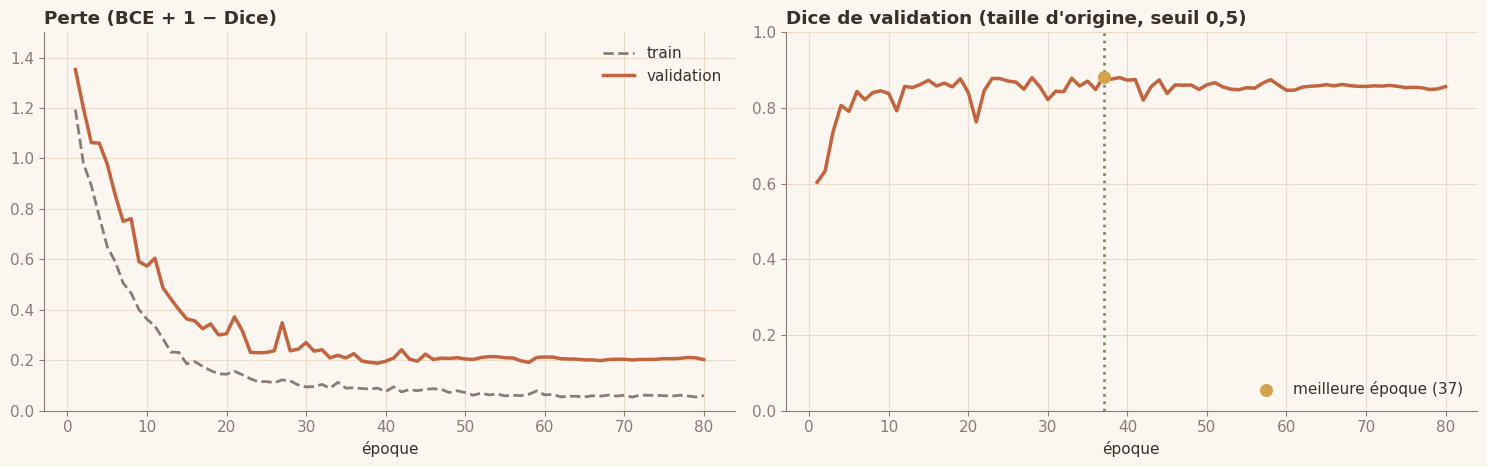

In [24]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

axes[0].plot(epochs, history["train_loss"], color=COLORS["taupe"], ls="--", lw=2, label="train")
axes[0].plot(epochs, history["val_loss"], color=COLORS["terracotta"], lw=2.5, label="validation")
axes[0].set_ylim(0, 1.5)
axes[0].set_title("Perte (BCE + 1 − Dice)")
axes[0].legend()

axes[1].plot(epochs, history["val_dice"], color=COLORS["terracotta"], lw=2.5)
axes[1].axvline(best_epoch, color=COLORS["sauge"], ls=":", lw=2)
axes[1].scatter([best_epoch], [max(history["val_dice"])], color=COLORS["ocre"], s=70, zorder=3,
                label=f"meilleure époque ({best_epoch})")
axes[1].set_ylim(0, 1)
axes[1].set_title("Dice de validation (taille d'origine, seuil 0,5)")
axes[1].legend(loc="lower right")

for ax in axes:
    ax.set_xlabel("époque")
finish(fig, name="courbes_entrainement")

La perte de validation reste au-dessus de celle du train, ce qui est normal : la validation est mesurée sur les images entières, sans augmentation. Le Dice de validation monte vite pendant les dix premières époques, atteint son meilleur niveau à l'époque 37, puis se stabilise un peu plus bas, autour de 0,86. C'est pour cela qu'on garde les poids de la meilleure époque plutôt que ceux de la dernière.

## $\color{#C2643F}{\mathbf{09}}$ &nbsp; Post-traitement, choisi sur la validation

On teste plusieurs réglages pour transformer la carte de probabilité en masque, **uniquement sur la validation** :

- **TTA** : moyenne des 8 orientations, ou une seule prédiction ;
- **seuil** sur la probabilité ;
- **surface minimale** : les taches plus petites sont supprimées, comme fausses détections.

Dans tous les cas, les trous à l'intérieur d'un glomérule sont bouchés.


> $\color{#55623F}{\bullet}$ **Règle de choix**
>
> Avec seulement 8 patchs de validation, un gain inférieur à 0,005 n'est pas significatif. On ne garde donc un réglage plus compliqué que s'il bat le réglage de base (pas de TTA, seuil 0,5, pas de filtre) d'au moins 0,005.

In [25]:
def postprocess(prob, threshold, min_area):
    """Seuillage, suppression des taches de surface < min_area, trous bouchés (contours extérieurs remplis)."""
    mask = (prob > threshold).astype(np.uint8)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    out = np.zeros_like(mask)
    for c in contours:
        if cv2.contourArea(c) >= min_area:
            cv2.drawContours(out, [c], -1, 1, thickness=cv2.FILLED)
    return out.astype(bool)


THRESHOLDS = [0.5, 0.4, 0.6, 0.3, 0.7]
MIN_AREAS = [0, 500, 1000, 2000, 4000]

val_probs = {tta: [predict_prob(model, data[p][0], tta) for p, _ in val_pairs] for tta in (False, True)}
val_masks = [data[p][1] for p, _ in val_pairs]

results = []                     # (Dice moyen, TTA, seuil, surface minimale)
for tta in (False, True):
    for t in THRESHOLDS:
        for a in MIN_AREAS:
            dices = [dice_np(postprocess(prob, t, a), m) for prob, m in zip(val_probs[tta], val_masks)]
            results.append((float(np.mean(dices)), tta, t, a))

baseline = best_result = results[0]
for r in results:
    if r[0] > best_result[0] + 0.005:
        best_result = r
val_dice_pp, USE_TTA, THRESHOLD, MIN_AREA = best_result

print(f"réglage de base (pas de TTA, seuil 0.5, pas de filtre) : Dice de validation {baseline[0]:.3f}")
print("5 meilleures combinaisons :")
for r in sorted(results, key=lambda r: -r[0])[:5]:
    print(f"    Dice {r[0]:.3f}   TTA {'oui' if r[1] else 'non'}   seuil {r[2]}   surface min. {r[3]}")
print(f"retenu : TTA {'oui' if USE_TTA else 'non'}, seuil {THRESHOLD}, surface min. {MIN_AREA}"
      f"  ->  Dice de validation {val_dice_pp:.3f}")

réglage de base (pas de TTA, seuil 0.5, pas de filtre) : Dice de validation 0.882
5 meilleures combinaisons :
    Dice 0.886   TTA oui   seuil 0.3   surface min. 0
    Dice 0.886   TTA oui   seuil 0.3   surface min. 500
    Dice 0.886   TTA oui   seuil 0.3   surface min. 1000
    Dice 0.885   TTA oui   seuil 0.4   surface min. 0
    Dice 0.885   TTA oui   seuil 0.4   surface min. 500
retenu : TTA non, seuil 0.5, surface min. 0  ->  Dice de validation 0.882


Le meilleur réglage (TTA et seuil 0,3) ne gagne que 0,004 sur le réglage de base, en dessous du seuil de 0,005 qu'on s'est fixé : on garde donc la règle la plus simple, sans TTA ni filtre.

## $\color{#C2643F}{\mathbf{10}}$ &nbsp; Évaluation sur le test

Tout est fixé avant cette cellule : les poids (meilleure époque sur la validation) et le post-traitement (section 09). Le Dice est calculé à la taille d'origine, comme dans le challenge. On compte aussi les glomérules, en séparant les taches du masque prédit (composantes connexes).

In [26]:
def predict_mask(model, img):
    """Masque binaire final : probabilité, puis post-traitement retenu sur la validation."""
    return postprocess(predict_prob(model, img, USE_TTA), THRESHOLD, MIN_AREA)


test_preds, test_scores, test_counts = [], [], []
for img_path, _ in test_pairs:
    img, true = data[img_path]
    pred = predict_mask(model, img)
    test_preds.append(pred)
    test_scores.append(dice_np(pred, true))
    test_counts.append((count_glomeruli(true), count_glomeruli(pred)))

print(f"{'patch':>5s}  {'Dice':>6s}  {'glomérules annotés':>18s}  {'prédits':>8s}")
for i, (score, (n_true, n_pred)) in enumerate(zip(test_scores, test_counts)):
    print(f"{i:5d}  {score:6.3f}  {n_true:18d}  {n_pred:8d}")
print(f"\nDice moyen sur le test : {np.mean(test_scores):.3f}")

patch    Dice  glomérules annotés   prédits
    0   0.955                   2         4
    1   0.972                   3         3
    2   0.898                   6         5
    3   0.948                   9         9
    4   0.406                   1         1
    5   0.947                   3         4
    6   0.976                   2         2
    7   0.964                  12        13

Dice moyen sur le test : 0.883


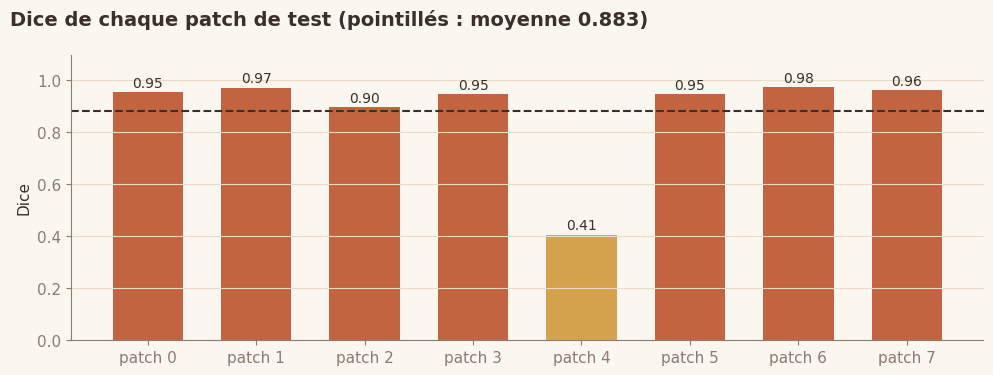

In [27]:
fig, ax = plt.subplots(figsize=(10, 3.8))
colors = [COLORS["terracotta"] if s >= 0.8 else COLORS["ocre"] for s in test_scores]
ax.bar(range(len(test_scores)), test_scores, color=colors, width=0.65)
ax.axhline(np.mean(test_scores), color=COLORS["encre"], ls="--", lw=1.5)
for i, s in enumerate(test_scores):
    ax.text(i, s + 0.02, f"{s:.2f}", ha="center", fontsize=10, color=COLORS["encre"])
ax.set_xticks(range(len(test_scores)))
ax.set_xticklabels([f"patch {i}" for i in range(len(test_scores))])
ax.set_ylim(0, 1.1)
ax.set_ylabel("Dice")
ax.grid(axis="x", visible=False)
finish(fig, f"Dice de chaque patch de test (pointillés : moyenne {np.mean(test_scores):.3f})", name="dice_test")

### Trois exemples : le meilleur patch, un patch médian et le plus difficile

Pour chaque patch : les glomérules annotés, les glomérules prédits, puis la carte des erreurs pixel par pixel.

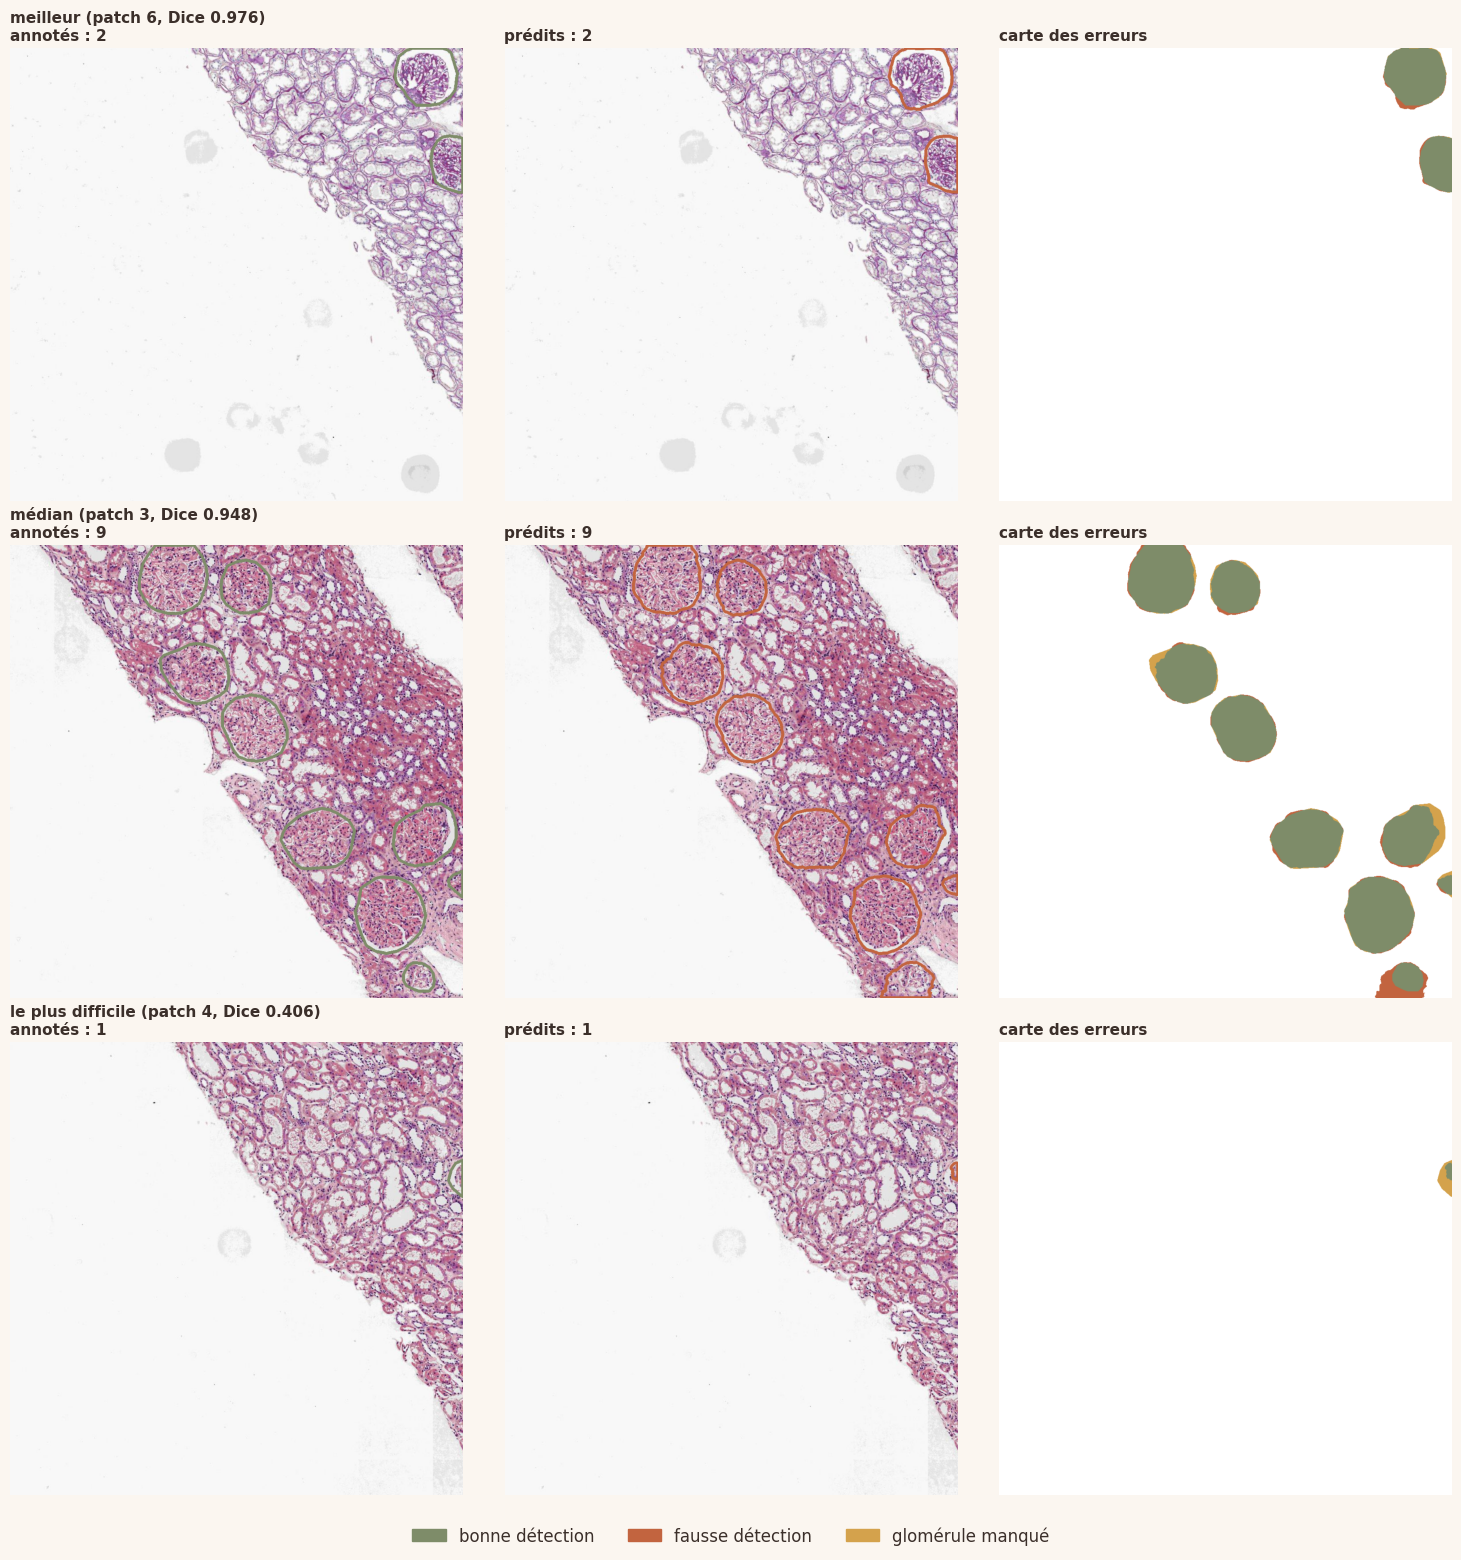

In [28]:
def error_map(true, pred):
    """Image RGB : bonne détection en sauge, fausse détection en terracotta, glomérule manqué en ocre."""
    view = np.zeros(true.shape + (3,), dtype=np.uint8)
    view[:] = 255                        # fond blanc
    view[true & pred] = RGB["sauge"]
    view[pred & ~true] = RGB["terracotta"]
    view[true & ~pred] = RGB["ocre"]
    return view


order = np.argsort(test_scores)[::-1]
picks = [("meilleur", order[0]), ("médian", order[len(order) // 2]), ("le plus difficile", order[-1])]

fig, axes = plt.subplots(len(picks), 3, figsize=(15, 5.2 * len(picks)))
for row, (label, i) in enumerate(picks):
    img, true = data[test_pairs[i][0]]
    pred = test_preds[i]
    n_true, n_pred = test_counts[i]
    axes[row, 0].imshow(draw_contours(img, true, RGB["sauge"]))
    axes[row, 0].set_title(f"{label} (patch {i}, Dice {test_scores[i]:.3f})\nannotés : {n_true}", fontsize=11)
    axes[row, 1].imshow(draw_contours(img, pred, RGB["terracotta"]))
    axes[row, 1].set_title(f"\nprédits : {n_pred}", fontsize=11)
    axes[row, 2].imshow(error_map(true, pred))
    axes[row, 2].set_title("\ncarte des erreurs", fontsize=11)
    for ax in axes[row]:
        ax.axis("off")

legend = [Patch(color=COLORS["sauge"], label="bonne détection"),
          Patch(color=COLORS["terracotta"], label="fausse détection"),
          Patch(color=COLORS["ocre"], label="glomérule manqué")]
fig.legend(handles=legend, loc="lower center", ncol=3, fontsize=12)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(ASSETS_DIR / "exemples_test.png", dpi=110, bbox_inches="tight")
plt.show()

## $\color{#C2643F}{\mathbf{11}}$ &nbsp; Bilan et suite

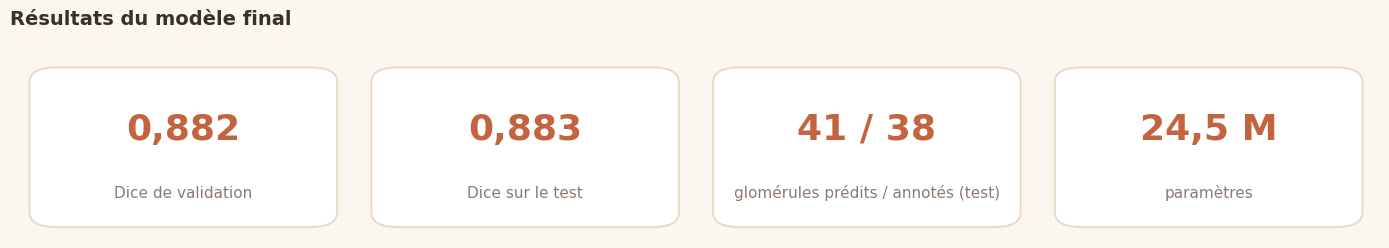

In [29]:
n_true_total = sum(n for n, _ in test_counts)
n_pred_total = sum(n for _, n in test_counts)
cards = [(f"{val_dice_pp:.3f}", "Dice de validation"),
         (f"{np.mean(test_scores):.3f}", "Dice sur le test"),
         (f"{n_pred_total} / {n_true_total}", "glomérules prédits / annotés (test)"),
         (f"{n_params / 1e6:.1f} M", "paramètres")]

fig, ax = plt.subplots(figsize=(14, 2.5))
ax.set_xlim(0, len(cards))
ax.set_ylim(0, 1)
ax.axis("off")
for i, (value, label) in enumerate(cards):
    ax.add_patch(FancyBboxPatch((i + 0.05, 0.06), 0.9, 0.88, boxstyle="round,pad=0,rounding_size=0.08",
                                facecolor="white", edgecolor=COLORS["sable"], lw=1.5))
    ax.text(i + 0.5, 0.6, value.replace(".", ","), ha="center", va="center",
            fontsize=26, fontweight="bold", color=COLORS["terracotta"])
    ax.text(i + 0.5, 0.25, label, ha="center", va="center", fontsize=11, color=COLORS["taupe"])
finish(fig, "Résultats du modèle final", name="resultats")

> $\color{#9A4A2E}{\bullet}$ **Ce qu'on retient**
>
> - Avec seulement 37 patchs d'entraînement, un encodeur **pré-entraîné sur ImageNet** et une augmentation adaptée (morceaux en pleine résolution, variations de coloration) donnent un Dice de 0,88 sur des patchs jamais vus, et 7 patchs de test sur 8 dépassent 0,89.
> - Entraîner et évaluer **à la taille d'origine** améliore le Dice sur le test par rapport à nos essais sur images réduites (0,883 contre 0,867), même si l'écart reste du même ordre que la variation d'un entraînement à l'autre.
> - Des améliorations plus lourdes (TTA, ensemble de 3 modèles) n'apportaient pas de gain significatif sur la validation : on a gardé le modèle le plus simple.

> $\color{#8A6420}{\bullet}$ **Limites**
>
> - Le test ne contient que 8 patchs : un seul cas difficile pèse lourd. Le patch 4 (Dice 0,41) contient un seul petit glomérule, coupé par le bord de l'image. Sans lui, le Dice moyen sur le test serait de 0,95.
> - Le modèle prédit 41 glomérules pour 38 annotés : quelques petites taches sont prises à tort pour des glomérules (4 prédits pour 2 sur le patch 0), et à l'inverse un glomérule n'est pas retrouvé sur le patch 2 (5 prédits pour 6).
> - Le filtre de surface minimale, qui supprimerait ces petites taches, n'a pas été retenu : son gain sur les 8 patchs de validation était trop faible pour être significatif.

> $\color{#55623F}{\bullet}$ **Suite du projet (en cours)**
>
> - Mieux détecter les **petits glomérules**, en particulier ceux coupés par le bord du patch, qui font le plus baisser le score : par exemple en tirant plus souvent des morceaux d'entraînement près des bords, ou en donnant plus de poids aux petits objets dans la fonction de perte.
> - Passer d'un masque binaire à une **segmentation d'instances**, avec un contour par glomérule, comme le demande l'énoncé du challenge.
> - Pour le classement du challenge, la même recette est réentraînée sur les 53 patchs et les masques sont encodés au format RLE (non repris ici).

---

*Annexe : sur Colab, la cellule suivante télécharge le dossier `assets/`, dont les figures sont reprises dans le README du dépôt.*

In [30]:
import shutil

shutil.make_archive("assets", "zip", ASSETS_DIR)
try:
    from google.colab import files
    files.download("assets.zip")
except ImportError:
    print("figures enregistrées dans le dossier assets/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>